<a href="https://colab.research.google.com/github/HafidzSetyawannn/Advanced-Mathematics-Assignment-06/blob/main/Tugas6_Menggunakan_5_Metode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Metode Numerik – Soal No. 2
Tentukan akar persamaan

$$f(x)=4x^3-15x^2+17x-6=0,\qquad x_0=3$$

menggunakan lima metode:

| Jenis | Metode |
|---|---|
| Tertutup | Bolzano (bagidua), Regula-Falsi |
| Terbuka | Lelaran Titik-Tetap, Newton-Raphson, Secant |

Nama / NIM : Muhammad Hafidz Setyawan / 265107080002

Turunan yang dipakai Newton-Raphson: $f'(x)=12x^2-30x+17$.

Karena tebakan awal $x_0=3$, semua metode diarahkan ke akar yang sama dengan hasil Newton-Raphson dari $x_0=3$, lalu hasilnya dibandingkan.

In [12]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:.6f}")
pd.set_option("display.width", 200)

def f(x):  return 4*x**3 - 15*x**2 + 17*x - 6
def df(x): return 12*x**2 - 30*x + 17

EPS = 1e-6
NMAKS = 100

## 0. Mencari selang yang memuat akar
Tabel nilai $f(x)$ pada titik-titik berjarak tetap $h=0{,}3$. Selang dengan tanda fungsi berbeda di ujung-ujungnya memuat akar.

       x      f(x)
0.000000 -6.000000
0.300000 -2.142000
0.600000 -0.336000
0.900000  0.066000
1.200000 -0.288000
1.500000 -0.750000
1.800000 -0.672000
2.100000  0.594000
2.400000  3.696000
2.700000  9.282000
3.000000 18.000000

Selang dengan perubahan tanda:
  [0.6, 0.9]   f(a) = -0.3360,  f(b) = +0.0660
  [0.9, 1.2]   f(a) = +0.0660,  f(b) = -0.2880
  [1.8, 2.1]   f(a) = -0.6720,  f(b) = +0.5940


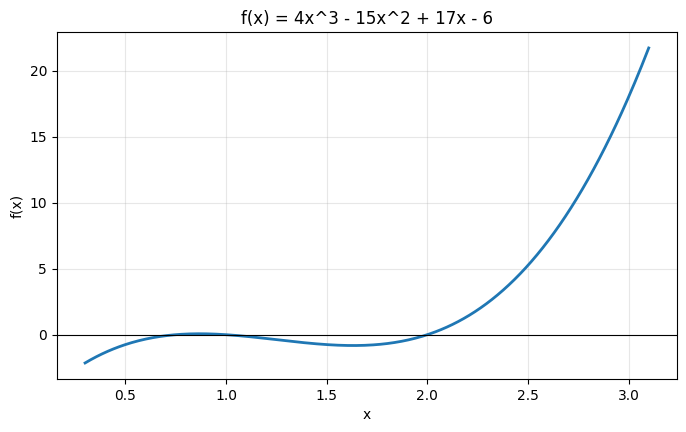

In [13]:
h = 0.3
xs = np.round(np.arange(0, 3.0 + h/2, h), 10)
tab_scan = pd.DataFrame({"x": xs, "f(x)": [f(x) for x in xs]})
print(tab_scan.to_string(index=False))

print("\nSelang dengan perubahan tanda:")
for i in range(1, len(xs)):
    if f(xs[i-1]) * f(xs[i]) < 0:
        print(f"  [{xs[i-1]:.1f}, {xs[i]:.1f}]   f(a) = {f(xs[i-1]):+.4f},  f(b) = {f(xs[i]):+.4f}")

xx = np.linspace(0.3, 3.1, 400)
plt.figure(figsize=(8, 4.5))
plt.plot(xx, f(xx), lw=2)
plt.axhline(0, color="k", lw=.8)
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title("f(x) = 4x^3 - 15x^2 + 17x - 6")
plt.grid(alpha=.3); plt.show()

Ada tiga selang: **[0,6; 0,9]**, **[0,9; 1,2]**, dan **[1,8; 2,1]**, jadi ada tiga akar. Karena Newton-Raphson dengan $x_0=3$ menuju akar di dekat 2, metode tertutup memakai selang **[1,8; 2,1]**.

Catatan: selang [0,6; 1,2] tidak bisa dipakai karena $f(0{,}6)\cdot f(1{,}2)>0$ padahal di dalamnya ada **dua** akar (banyaknya akar genap, seperti Gambar 3.2 pada materi). Ini contoh bahwa $f(a)f(b)>0$ tidak menjamin tidak ada akar.

## 1. Metode Bolzano (Bagidua)
Selang $[a,b]$ dibagi dua di $c=(a+b)/2$, lalu diambil upaselang yang ujung-ujungnya berbeda tanda. Berhenti jika $|b-a|<\varepsilon$ atau $f(c)\approx0$ (titik tengah tepat di akar).

In [14]:
def bolzano(a, b, eps=EPS, eps_f=1e-12, nmaks=NMAKS):
    baris, hist = [], []
    for r in range(nmaks):
        c = (a + b) / 2
        fa, fc, fb = f(a), f(c), f(b)
        if fa * fc < 0:
            baru, a_baru, b_baru = "[a, c]", a, c
        else:
            baru, a_baru, b_baru = "[c, b]", c, b
        lebar = abs(b_baru - a_baru)
        baris.append([r, a, c, b, fa, fc, fb, baru, lebar])
        hist.append(c)
        a, b = a_baru, b_baru
        if lebar < eps or abs(fc) < eps_f:
            break
    tab = pd.DataFrame(baris, columns=["r","a","c","b","f(a)","f(c)","f(b)","selang baru","lebar"]).set_index("r")
    return c, tab, hist

akar_bz, tab_bz, hist_bz = bolzano(1.8, 2.1)
print(tab_bz.to_string())
print(f"\nAkar (Bolzano) = {akar_bz:.6f},  {len(tab_bz)} lelaran")

          a        c        b      f(a)      f(c)     f(b) selang baru    lebar
r                                                                              
0  1.800000 1.950000 2.100000 -0.672000 -0.228000 0.594000      [c, b] 0.150000
1  1.950000 2.025000 2.100000 -0.228000  0.130687 0.594000      [a, c] 0.075000
2  1.950000 1.987500 2.025000 -0.228000 -0.061102 0.130687      [c, b] 0.037500
3  1.987500 2.006250 2.025000 -0.061102  0.031603 0.130687      [a, c] 0.018750
4  1.987500 1.996875 2.006250 -0.061102 -0.015537 0.031603      [c, b] 0.009375
5  1.996875 2.001563 2.006250 -0.015537  0.007834 0.031603      [a, c] 0.004687
6  1.996875 1.999219 2.001563 -0.015537 -0.003901 0.007834      [c, b] 0.002344
7  1.999219 2.000391 2.001563 -0.003901  0.001954 0.007834      [a, c] 0.001172
8  1.999219 1.999805 2.000391 -0.003901 -0.000976 0.001954      [c, b] 0.000586
9  1.999805 2.000098 2.000391 -0.000976  0.000488 0.001954      [a, c] 0.000293
10 1.999805 1.999951 2.000098 -0.000976 

## 2. Metode Regula-Falsi
Garis lurus dari $(a,f(a))$ ke $(b,f(b))$ dipotongkan dengan sumbu-$x$:

$$c=b-\frac{f(b)\,(b-a)}{f(b)-f(a)}$$

Algoritma sama dengan Bolzano, hanya perhitungan $c$ yang berbeda. Berhenti jika $|c_{baru}-c_{lama}|<\varepsilon$ atau $|f(c)|$ sangat kecil. (Lebar selang tidak dipakai karena pada regula-falsi satu ujung selang cenderung tidak bergerak.)

In [15]:
def regula_falsi(a, b, eps=EPS, eps_f=1e-10, nmaks=NMAKS):
    baris, hist = [], []
    c_lama = None
    for r in range(nmaks):
        fa, fb = f(a), f(b)
        c = b - fb * (b - a) / (fb - fa)
        fc = f(c)
        if fa * fc < 0:
            baru, a_baru, b_baru = "[a, c]", a, c
        else:
            baru, a_baru, b_baru = "[c, b]", c, b
        selisih = np.nan if c_lama is None else abs(c - c_lama)
        baris.append([r, a, c, b, fa, fc, fb, baru, selisih])
        hist.append(c)
        a, b, c_lama = a_baru, b_baru, c
        if abs(fc) < eps_f or (not np.isnan(selisih) and selisih < eps):
            break
    tab = pd.DataFrame(baris, columns=["r","a","c","b","f(a)","f(c)","f(b)","selang baru","|c_baru - c_lama|"]).set_index("r")
    return c, tab, hist

akar_rf, tab_rf, hist_rf = regula_falsi(1.8, 2.1)
print(tab_rf.to_string())
print(f"\nAkar (Regula-Falsi) = {akar_rf:.6f},  {len(tab_rf)} lelaran")

         a        c        b      f(a)      f(c)     f(b) selang baru  |c_baru - c_lama|
r                                                                                       
0 1.800000 1.959242 2.100000 -0.672000 -0.189111 0.594000      [c, b]                NaN
1 1.959242 1.993233 2.100000 -0.189111 -0.033424 0.594000      [c, b]           0.033991
2 1.993233 1.998921 2.100000 -0.033424 -0.005386 0.594000      [c, b]           0.005688
3 1.998921 1.999829 2.100000 -0.005386 -0.000855 0.594000      [c, b]           0.000908
4 1.999829 1.999973 2.100000 -0.000855 -0.000135 0.594000      [c, b]           0.000144
5 1.999973 1.999996 2.100000 -0.000135 -0.000021 0.594000      [c, b]           0.000023
6 1.999996 1.999999 2.100000 -0.000021 -0.000003 0.594000      [c, b]           0.000004
7 1.999999 2.000000 2.100000 -0.000003 -0.000001 0.594000      [c, b]           0.000001

Akar (Regula-Falsi) = 2.000000,  8 lelaran


## 3. Metode Lelaran Titik-Tetap
Susun $f(x)=0$ menjadi $x=g(x)$, lalu lelar $x_{r+1}=g(x_r)$. Syarat konvergen: $|g'(x)|<1$ di sekitar akar. Ada banyak cara menyusun $g(x)$; tiga di antaranya:

| | $g(x)$ | Cara memperolehnya |
|---|---|---|
| A | $\dfrac{15}{4}-\dfrac{17}{4x}+\dfrac{6}{4x^2}$ | $4x^3=15x^2-17x+6$, bagi $4x^2$ |
| B | $\dfrac{-4x^3+15x^2+6}{17}$ | $17x=-4x^3+15x^2+6$ |
| C | $x+f(x)=4x^3-15x^2+18x-6$ | tambahkan $x$ di kedua ruas |

Turunannya: $g_A'=\dfrac{17}{4x^2}-\dfrac{3}{x^3}$, $\;g_B'=\dfrac{-12x^2+30x}{17}$, $\;g_C'=1+f'(x)$.

In [16]:
gA  = lambda x: 15/4 - 17/(4*x) + 6/(4*x**2)
gB  = lambda x: (-4*x**3 + 15*x**2 + 6) / 17
gC  = lambda x: x + f(x)
dgA = lambda x: 17/(4*x**2) - 3/x**3
dgB = lambda x: (-12*x**2 + 30*x) / 17
dgC = lambda x: 1 + df(x)

def titik_tetap(g, x0, eps=EPS, nmaks=NMAKS):
    baris, hist = [[0, x0, np.nan]], [x0]
    x, ok = x0, False
    for r in range(1, nmaks + 1):
        try:
            x_baru = g(x)
        except (ZeroDivisionError, OverflowError):
            break
        baris.append([r, x_baru, abs(x_baru - x)])
        hist.append(x_baru)
        if abs(x_baru - x) < eps:
            x, ok = x_baru, True
            break
        x = x_baru
        if abs(x) > 1e6:
            break
    tab = pd.DataFrame(baris, columns=["r","x_r","|x_r+1 - x_r|"]).set_index("r")
    return x, tab, hist, ok

print("Perbandingan susunan g(x), x0 = 3, akar yang dituju x = 2:\n")
baris = []
for nama, g, dg in [("A", gA, dgA), ("B", gB, dgB), ("C", gC, dgC)]:
    x, t, _, ok = titik_tetap(g, 3.0)
    d = dg(2.0)
    if 0 < d < 1:    jenis = "konvergen monoton"
    elif -1 < d < 0: jenis = "konvergen berosilasi"
    elif d >= 1:     jenis = "divergen monoton"
    else:            jenis = "divergen berosilasi"
    baris.append([nama, f"{d:.4f}", jenis, "konvergen" if ok else "DIVERGEN",
                  f"{x:.6f}" if ok else "-", len(t)-1])
print(pd.DataFrame(baris, columns=["g(x)", "g'(2)", "Prediksi teori", "Hasil", "Akar", "Lelaran"]).to_string(index=False))

Perbandingan susunan g(x), x0 = 3, akar yang dituju x = 2:

g(x)  g'(2)    Prediksi teori     Hasil     Akar  Lelaran
   A 0.6875 konvergen monoton konvergen 2.000002       33
   B 0.7059 konvergen monoton konvergen 1.999998       31
   C 6.0000  divergen monoton  DIVERGEN        -        3


In [17]:
# Susunan A (konvergen monoton) dipakai sebagai hasil Titik-Tetap
akar_fp, tab_fp, hist_fp, ok_fp = titik_tetap(gA, 3.0)
print(tab_fp.head(10).to_string())
print("   ...")
print(tab_fp.tail(3).to_string())
print(f"\nAkar (Titik-Tetap, susunan A) = {akar_fp:.6f},  {len(tab_fp)-1} lelaran")

# Demonstrasi susunan C yang divergen
_, tab_C, _, _ = titik_tetap(gC, 3.0, nmaks=6)
print("\nSusunan C (divergen), 6 lelaran pertama:")
print(tab_C.to_string(float_format=lambda v: f"{v:.4g}"))

       x_r  |x_r+1 - x_r|
r                        
0 3.000000            NaN
1 2.500000       0.500000
2 2.290000       0.210000
3 2.180141       0.109859
4 2.116174       0.063967
5 2.076615       0.039559
6 2.051240       0.025375
7 2.034581       0.016658
8 2.023479       0.011102
9 2.016005       0.007474
   ...
        x_r  |x_r+1 - x_r|
r                         
31 2.000004       0.000002
32 2.000003       0.000001
33 2.000002       0.000001

Akar (Titik-Tetap, susunan A) = 2.000002,  33 lelaran

Susunan C (divergen), 6 lelaran pertama:
        x_r  |x_r+1 - x_r|
r                         
0         3            NaN
1        21             18
2  3.08e+04      3.078e+04
3 1.169e+14      1.169e+14


Susunan A dipakai karena $0<g_A'(2)\approx0{,}69<1$ (konvergen monoton). Susunan B juga konvergen ($g_B'(2)\approx0{,}71$), tetapi berosilasi. Susunan C divergen karena $g_C'(2)=1+f'(2)=6>1$. Konvergensi titik-tetap bersifat linear dengan rasio sekitar $|g'(2)|$, sehingga di sini butuh puluhan lelaran.

## 4. Metode Newton-Raphson

$$x_{r+1}=x_r-\frac{f(x_r)}{f'(x_r)}$$

In [18]:
def newton_raphson(x0, eps=EPS, nmaks=NMAKS):
    baris, hist = [], []
    x = x0
    for r in range(nmaks):
        fx, dfx = f(x), df(x)
        if dfx == 0:
            raise ZeroDivisionError("f'(x) = 0")
        x_baru = x - fx/dfx
        selisih = abs(x_baru - x)
        baris.append([r, x, fx, dfx, x_baru, selisih])
        hist.append(x_baru)
        x = x_baru
        if selisih < eps:
            break
    tab = pd.DataFrame(baris, columns=["r","x_r","f(x_r)","f'(x_r)","x_r+1","|x_r+1 - x_r|"]).set_index("r")
    return x, tab, hist

akar_nr, tab_nr, hist_nr = newton_raphson(3.0)
print(tab_nr.to_string())
print(f"\nAkar (Newton-Raphson) = {akar_nr:.6f},  {len(tab_nr)} lelaran")

# Rasio galat: e_{r+1} / e_r^2 -> f''(2) / (2 f'(2)) = 18/10 = 1.8
e = np.abs(np.array([3.0] + hist_nr) - 2.0)
print("\nRasio e_{r+1}/e_r^2 (teori -> 1,8):")
for i in range(len(e) - 1):
    if e[i] > 1e-6:
        print(f"  r={i}: {e[i+1]/e[i]**2:.4f}")

       x_r    f(x_r)   f'(x_r)    x_r+1  |x_r+1 - x_r|
r                                                     
0 3.000000 18.000000 35.000000 2.485714       0.514286
1 2.485714  5.010192 16.573878 2.183420       0.302295
2 2.183420  1.244567  8.705269 2.040453       0.142967
3 2.040453  0.217256  5.747785 2.002654       0.037798
4 2.002654  0.013336  5.047865 2.000013       0.002642
5 2.000013  0.000063  5.000227 2.000000       0.000013
6 2.000000  0.000000  5.000000 2.000000       0.000000

Akar (Newton-Raphson) = 2.000000,  7 lelaran

Rasio e_{r+1}/e_r^2 (teori -> 1,8):
  r=0: 0.4857
  r=1: 0.7775
  r=2: 1.2024
  r=3: 1.6221
  r=4: 1.7871
  r=5: 1.7999


## 5. Metode Secant
Turunan pada Newton-Raphson diganti dengan hampiran beda hingga, sehingga $f'(x)$ tidak diperlukan, tetapi butuh dua tebakan awal yang **tidak harus mengurung akar**:

$$x_{r+1}=x_r-\frac{f(x_r)\,(x_r-x_{r-1})}{f(x_r)-f(x_{r-1})}$$

Tebakan awal yang dipakai: $x_0=3$ dan $x_1=2{,}5$.

In [19]:
def secant(x0, x1, eps=EPS, nmaks=NMAKS):
    baris, hist = [], []
    for r in range(1, nmaks + 1):
        f0, f1 = f(x0), f(x1)
        if f1 == f0:
            raise ZeroDivisionError("f(x_r) = f(x_r-1)")
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        selisih = abs(x2 - x1)
        baris.append([r, x0, x1, f0, f1, x2, selisih])
        hist.append(x2)
        x0, x1 = x1, x2
        if selisih < eps:
            break
    tab = pd.DataFrame(baris, columns=["r","x_r-1","x_r","f(x_r-1)","f(x_r)","x_r+1","|x_r+1 - x_r|"]).set_index("r")
    return x1, tab, hist

akar_sc, tab_sc, hist_sc = secant(3.0, 2.5)
print(tab_sc.to_string())
print(f"\nAkar (Secant) = {akar_sc:.6f},  {len(tab_sc)} lelaran")

     x_r-1      x_r  f(x_r-1)   f(x_r)    x_r+1  |x_r+1 - x_r|
r                                                             
1 3.000000 2.500000 18.000000 5.250000 2.294118       0.205882
2 2.500000 2.294118  5.250000 2.350906 2.127165       0.166952
3 2.294118 2.127165  2.350906 0.789593 2.042734       0.084432
4 2.127165 2.042734  0.789593 0.230417 2.007942       0.034791
5 2.042734 2.007942  0.230417 0.040282 2.000572       0.007371
6 2.007942 2.000572  0.040282 0.002861 2.000008       0.000563
7 2.000572 2.000008  0.002861 0.000040 2.000000       0.000008
8 2.000008 2.000000  0.000040 0.000000 2.000000       0.000000

Akar (Secant) = 2.000000,  8 lelaran


## 6. Perbandingan Kelima Metode
Akar sejati diperoleh dari faktorisasi $4x^3-15x^2+17x-6=(x-2)(4x-3)(x-1)$, jadi akarnya $x=2$, $x=1$, dan $x=0{,}75$. Nilai $x=2$ dipakai sebagai acuan untuk menghitung galat.

Akar sejati (numpy.roots): [0.75 1.   2.  ]

                      Jenis Tebakan/selang awal  Akar  Lelaran      |f(x)|  Galat |x-2|
Metode                                                                                 
Bolzano (bagidua)  Tertutup          [1,8; 2,1]     2       19 9.53674e-07  1.90735e-07
Regula-Falsi       Tertutup          [1,8; 2,1]     2        8 5.36375e-07  1.07275e-07
Titik-Tetap (A)     Terbuka              x0 = 3     2       33 9.76686e-06  1.95337e-06
Newton-Raphson      Terbuka              x0 = 3     2        7           0            0
Secant              Terbuka        x0=3, x1=2,5     2        8 6.03961e-13   1.2168e-13


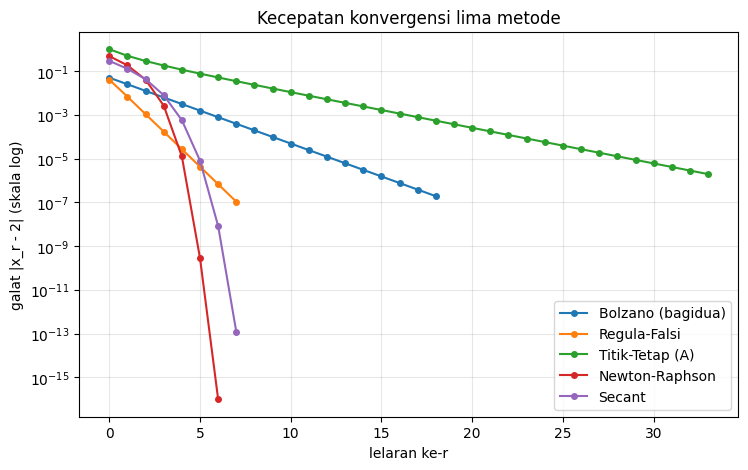

In [20]:
print("Akar sejati (numpy.roots):", np.sort(np.roots([4, -15, 17, -6])))
x_ref = 2.0

hasil = [
    ("Bolzano (bagidua)", "Tertutup", "[1,8; 2,1]",   akar_bz, len(tab_bz),     hist_bz),
    ("Regula-Falsi",      "Tertutup", "[1,8; 2,1]",   akar_rf, len(tab_rf),     hist_rf),
    ("Titik-Tetap (A)",   "Terbuka",  "x0 = 3",       akar_fp, len(tab_fp) - 1, hist_fp),
    ("Newton-Raphson",    "Terbuka",  "x0 = 3",       akar_nr, len(tab_nr),     hist_nr),
    ("Secant",            "Terbuka",  "x0=3, x1=2,5", akar_sc, len(tab_sc),     hist_sc),
]
perbandingan = pd.DataFrame([{
    "Metode": n, "Jenis": j, "Tebakan/selang awal": ia, "Akar": a,
    "Lelaran": k, "|f(x)|": abs(f(a)), "Galat |x-2|": abs(a - x_ref)
} for n, j, ia, a, k, _ in hasil]).set_index("Metode")
print()
print(perbandingan.to_string(float_format=lambda v: f"{v:.6g}"))

plt.figure(figsize=(8.5, 5))
for n, j, ia, a, k, hist in hasil:
    err = np.maximum(np.abs(np.array(hist) - x_ref), 1e-16)
    plt.semilogy(range(len(err)), err, "o-", ms=4, label=n)
plt.xlabel("lelaran ke-r"); plt.ylabel("galat |x_r - 2| (skala log)")
plt.title("Kecepatan konvergensi lima metode"); plt.grid(alpha=.3, which="both"); plt.legend(); plt.show()

## 7. Akar-akar lain
Dua akar lainnya ($x=0{,}75$ dan $x=1$) dapat ditemukan dengan selang atau tebakan awal yang berbeda.

In [21]:
print("Metode tertutup pada selang lain:")
for a, b in [(0.6, 0.9), (0.9, 1.2), (1.8, 2.1)]:
    r1, t1, _ = bolzano(a, b)
    r2, t2, _ = regula_falsi(a, b)
    print(f"  [{a}, {b}]: Bolzano = {r1:.6f} ({len(t1)} lelaran),  Regula-Falsi = {r2:.6f} ({len(t2)} lelaran)")

print("\nNewton-Raphson dengan tebakan awal berbeda:")
for x0 in [0.0, 0.5, 0.9, 1.2, 1.5, 3.0]:
    a, t, _ = newton_raphson(x0)
    print(f"  x0 = {x0}: akar = {a:.6f}  ({len(t)} lelaran)")

Metode tertutup pada selang lain:
  [0.6, 0.9]: Bolzano = 0.750000 (1 lelaran),  Regula-Falsi = 0.750000 (17 lelaran)
  [0.9, 1.2]: Bolzano = 1.000000 (19 lelaran),  Regula-Falsi = 1.000000 (11 lelaran)
  [1.8, 2.1]: Bolzano = 2.000000 (19 lelaran),  Regula-Falsi = 2.000000 (8 lelaran)

Newton-Raphson dengan tebakan awal berbeda:
  x0 = 0.0: akar = 0.750000  (8 lelaran)
  x0 = 0.5: akar = 0.750000  (6 lelaran)
  x0 = 0.9: akar = 1.000000  (6 lelaran)
  x0 = 1.2: akar = 1.000000  (5 lelaran)
  x0 = 1.5: akar = 0.750000  (2 lelaran)
  x0 = 3.0: akar = 2.000000  (7 lelaran)


## Kesimpulan
- Dengan $x_0=3$, Newton-Raphson menemukan akar **$x=2$** dalam 7 lelaran. Hasil ini cocok dengan faktorisasi $(x-2)(4x-3)(x-1)$, dan kelima metode menghasilkan akar yang sama sampai enam angka desimal.
- **Metode tertutup** selalu konvergen asalkan selang mengurung akar. Selang [1,8; 2,1] ditemukan dari tabel nilai fungsi. Bolzano butuh banyak lelaran karena hanya membagi selang dua; Regula-Falsi memakai nilai $f(a)$ dan $f(b)$ sehingga lebih cepat.
- **Newton-Raphson** konvergen kuadratik (rasio galat mendekati 1,8 sesuai teori), tetapi memerlukan $f'(x)$ dan bergantung pada tebakan awal. **Secant** tidak perlu turunan dan tidak perlu mengurung akar; ordenya sedikit di bawah Newton-Raphson.
- **Titik-Tetap** sangat bergantung pada susunan $g(x)$: susunan A dan B konvergen ($|g'(2)|<1$) tetapi lambat (linear), sedangkan susunan C divergen ($g'(2)=6$).